# 🎓 Student Performance Prediction & Analysis
### Powered by Apache Spark MLlib

---

**Cluster Computing Project**

A Machine Learning project focused on analyzing student academic performance, predicting final grades, classifying pass/fail outcomes, and discovering student groups using Apache Spark.

**Project Information**

- **Project Title:** Student Performance Prediction and Analysis using Apache Spark MLlib
- **Technology:** Python, PySpark, Apache Spark MLlib
- **Environment:** VS Code & Jupyter Notebook
- **Dataset:** UCI Student Performance Dataset — Portuguese Students
- **Dataset Size:** 649 records and 33 columns

---

### 🎯 Project Goal

To explore student academic data and apply machine learning algorithms to predict final grades, classify pass/fail outcomes, and identify patterns in student performance.

> *Turning student data into meaningful academic insights.*

In [ ]:
from pyspark.sql import SparkSession
spark = SparkSession.builder \
    .appName("StudentPerformanceAnalysis") \
    .master("local[*]") \
    .getOrCreate()

# Load the dataset
df = spark.read \
    .option("header", "true") \
    .option("sep", ";") \
    .option("inferSchema", "true") \
    .csv("data/student-por.csv")

# Display dataset information
print("Total Records:", df.count())
print("Total Columns:", len(df.columns))

print("\nDataset Schema:")
df.printSchema()

print("\nFirst 10 Student Records:")
df.show(10, truncate=False)

26/10/13 04:24:02 WARN Utils: Your hostname, Jatins-MacBook-Air-4.local resolves to a loopback address: 127.0.0.1; using 192.168.1.45 instead (on interface en0)
26/10/13 04:24:02 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/13 04:24:02 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Total Records: 649
Total Columns: 33

Dataset Schema:
root
 |-- school: string (nullable = true)
 |-- sex: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- address: string (nullable = true)
 |-- famsize: string (nullable = true)
 |-- Pstatus: string (nullable = true)
 |-- Medu: integer (nullable = true)
 |-- Fedu: integer (nullable = true)
 |-- Mjob: string (nullable = true)
 |-- Fjob: string (nullable = true)
 |-- reason: string (nullable = true)
 |-- guardian: string (nullable = true)
 |-- traveltime: integer (nullable = true)
 |-- studytime: integer (nullable = true)
 |-- failures: integer (nullable = true)
 |-- schoolsup: string (nullable = true)
 |-- famsup: string (nullable = true)
 |-- paid: string (nullable = true)
 |-- activities: string (nullable = true)
 |-- nursery: string (nullable = true)
 |-- higher: string (nullable = true)
 |-- internet: string (nullable = true)
 |-- romantic: string (nullable = true)
 |-- famrel: integer (nullable = true)
 |-- freetim

26/10/13 04:24:06 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


## 🔍 2. Data Inspection & Quality Check

Inspect column names, data types, duplicate records, and missing values to understand the dataset quality.

In [3]:
from pyspark.sql import functions as F

# Display column names
print("Column names:")
print(df.columns)

# Show data types
print("\nData types:")
df.printSchema()

# Count duplicate rows
print("\nDuplicate rows:", 
      df.count() - df.dropDuplicates().count())

# Check missing values
print("\nMissing values by column:")
df.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in df.columns
]).show(truncate=False)


Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Data types:
root
 |-- school: string (nullable = true)
 |-- sex: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- address: string (nullable = true)
 |-- famsize: string (nullable = true)
 |-- Pstatus: string (nullable = true)
 |-- Medu: integer (nullable = true)
 |-- Fedu: integer (nullable = true)
 |-- Mjob: string (nullable = true)
 |-- Fjob: string (nullable = true)
 |-- reason: string (nullable = true)
 |-- guardian: string (nullable = true)
 |-- traveltime: integer (nullable = true)
 |-- studytime: integer (nullable = true)
 |-- failures: integer (nullable = true)
 |-- schoolsup: string (nullable = true)
 |-- famsup: string (nu

## 📊 3. Grade Statistics & Distribution

Analyze G1, G2, and G3 using descriptive statistics and examine the distribution of students' final grades.

In [4]:
print("Grade statistics:")

df.select("G1", "G2", "G3").describe().show()

print("Final grade distribution:")

df.groupBy("G3") \
  .count() \
  .orderBy("G3") \
  .show(25)


Grade statistics:
+-------+------------------+------------------+------------------+
|summary|                G1|                G2|                G3|
+-------+------------------+------------------+------------------+
|  count|               649|               649|               649|
|   mean|11.399075500770415|11.570107858243452|11.906009244992296|
| stddev|2.7452651284463707| 2.913638664303866| 3.230656242804805|
|    min|                 0|                 0|                 0|
|    max|                19|                19|                19|
+-------+------------------+------------------+------------------+

Final grade distribution:
+---+-----+
| G3|count|
+---+-----+
|  0|   15|
|  1|    1|
|  5|    1|
|  6|    3|
|  7|   10|
|  8|   35|
|  9|   35|
| 10|   97|
| 11|  104|
| 12|   72|
| 13|   82|
| 14|   63|
| 15|   49|
| 16|   36|
| 17|   29|
| 18|   15|
| 19|    2|
+---+-----+



### 📈 3.1 Final Grade Distribution

Visualize the number of students at each final grade (`G3`) using a bar chart.

CodeCache: size=131072Kb used=32781Kb max_used=32789Kb free=98290Kb
 bounds [0x00000001079f8000, 0x0000000109a28000, 0x000000010f9f8000]
 total_blobs=11265 nmethods=10284 adapters=894
 compilation: disabled (not enough contiguous free space left)


Java HotSpot(TM) 64-Bit Server VM warning: CodeCache is full. Compiler has been disabled.
Java HotSpot(TM) 64-Bit Server VM warning: Try increasing the code cache size using -XX:ReservedCodeCacheSize=


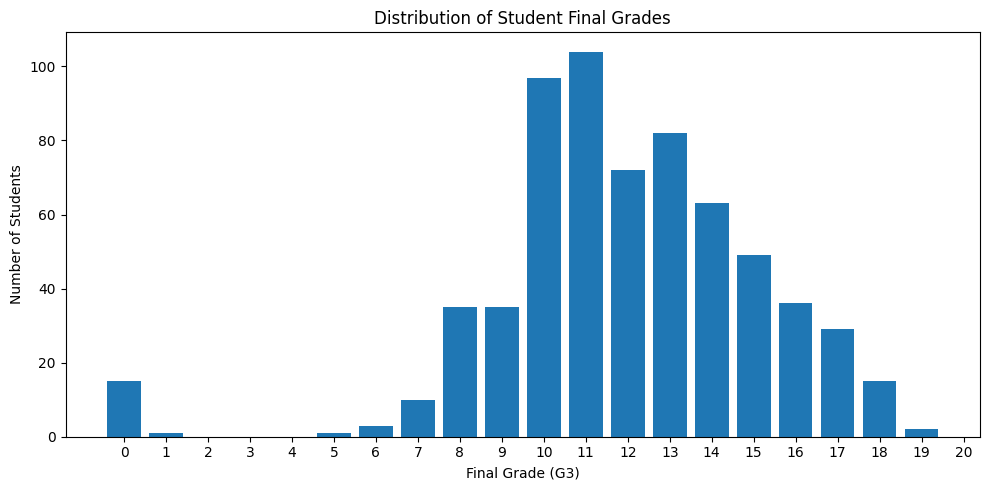

In [5]:
import matplotlib.pyplot as plt
grade_data = (
    df.groupBy("G3")
      .count()
      .orderBy("G3")
      .toPandas()
)

plt.figure(figsize=(10, 5))
plt.bar(grade_data["G3"], grade_data["count"])
plt.title("Distribution of Student Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.xticks(range(0, 21))
plt.tight_layout()
plt.show()


### 🔥 3.2 Correlation Heatmap

Visualize correlations between numerical student attributes and academic grades using a heatmap.

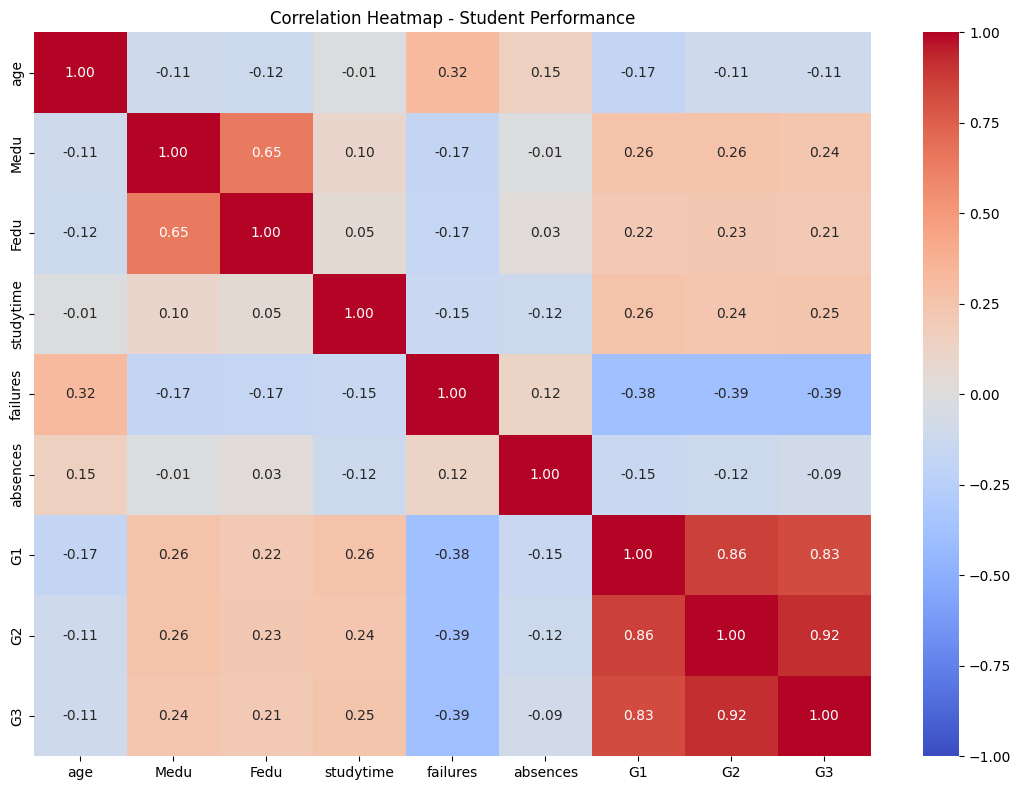

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import functions as F

# Select numerical columns
numeric_cols = [
    "age", "Medu", "Fedu", "studytime",
    "failures", "absences", "G1", "G2", "G3"
]

# Calculate correlation matrix using Spark
correlation_values = []

for col1 in numeric_cols:
    row = []
    for col2 in numeric_cols:
        row.append(df.stat.corr(col1, col2))
    correlation_values.append(row)

# Convert results into a Pandas DataFrame
import pandas as pd

corr_df = pd.DataFrame(
    correlation_values,
    index=numeric_cols,
    columns=numeric_cols
)

# Plot heatmap
plt.figure(figsize=(11, 8))
sns.heatmap(
    corr_df,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap - Student Performance")
plt.tight_layout()
plt.show()


### 📋 3.3 Final Grade Summary & Pass/Fail Distribution

Summarize final grades and count students scoring at least 10 marks as passing.

In [7]:
from pyspark.sql import functions as F
# Target variable: final grade
print("Final Grade Summary")

df.select(
    F.mean("G3").alias("Average_Final_Grade"),
    F.min("G3").alias("Minimum_Final_Grade"),
    F.max("G3").alias("Maximum_Final_Grade"),
    F.stddev("G3").alias("StdDev_Final_Grade")
).show()

# Check how many students have G3 >= 10
df.withColumn(
    "Pass",
    F.when(F.col("G3") >= 10, 1).otherwise(0)
).groupBy("Pass").count().show()


Final Grade Summary
+-------------------+-------------------+-------------------+------------------+
|Average_Final_Grade|Minimum_Final_Grade|Maximum_Final_Grade|StdDev_Final_Grade|
+-------------------+-------------------+-------------------+------------------+
| 11.906009244992296|                  0|                 19| 3.230656242804805|
+-------------------+-------------------+-------------------+------------------+

+----+-----+
|Pass|count|
+----+-----+
|   1|  549|
|   0|  100|
+----+-----+



## 🤖 4. Linear Regression — Grade Prediction

Prepare input features and target variable (`G3`) for training a Linear Regression model.

In [8]:

from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

print("Linear Regression libraries imported successfully!")


Linear Regression libraries imported successfully!


### ⚙️ 4.1 Feature Selection

Select student attributes as input features and `G3` as the target for grade prediction.

In [9]:
# Input features
feature_cols = [
    "age",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2"
]

# Target column
target_col = "G3"

print("Input Features:", feature_cols)
print("Target Column:", target_col)

df.select(feature_cols + [target_col]).show(5)

Input Features: ['age', 'studytime', 'failures', 'absences', 'G1', 'G2']
Target Column: G3
+---+---------+--------+--------+---+---+---+
|age|studytime|failures|absences| G1| G2| G3|
+---+---------+--------+--------+---+---+---+
| 18|        2|       0|       4|  0| 11| 11|
| 17|        2|       0|       2|  9| 11| 11|
| 15|        2|       0|       6| 12| 13| 12|
| 15|        3|       0|       0| 14| 14| 14|
| 16|        2|       0|       0| 11| 13| 13|
+---+---------+--------+--------+---+---+---+
only showing top 5 rows



### ✂️ 4.2 Train-Test Split

Split the dataset into 80% training data and 20% testing data for model evaluation.

In [10]:
train_df, test_df = df.randomSplit([0.8, 0.2], seed=42)

print("Training records:", train_df.count())
print("Testing records:", test_df.count())

Training records: 544
Testing records: 105


### ⚙️ 4.3 Feature Vectorization

Convert selected input columns into a feature vector using Spark's `VectorAssembler`.

In [11]:
assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

train_data = assembler.transform(train_df)
test_data = assembler.transform(test_df)

train_data.select("features", "G3").show(5, truncate=False)

+----------------------------+---+
|features                    |G3 |
+----------------------------+---+
|[15.0,4.0,0.0,4.0,13.0,13.0]|13 |
|[15.0,1.0,1.0,2.0,8.0,9.0]  |9  |
|[15.0,1.0,0.0,8.0,14.0,13.0]|12 |
|[15.0,3.0,0.0,2.0,10.0,11.0]|10 |
|[15.0,3.0,0.0,2.0,13.0,13.0]|13 |
+----------------------------+---+
only showing top 5 rows



### 🧠 4.4 Train Linear Regression Model

Train the Linear Regression model using the prepared training dataset.

In [12]:
lr = LinearRegression(
    featuresCol="features",
    labelCol="G3",
    maxIter=100,
    regParam=0.01
)

lr_model = lr.fit(train_data)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


26/10/13 04:24:11 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/10/13 04:24:12 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.lapack.JNILAPACK


### 🔮 4.5 Grade Prediction

In [13]:
predictions = lr_model.transform(test_data)

predictions.select(
    "G3", "prediction"
).show(10, truncate=False)

+---+------------------+
|G3 |prediction        |
+---+------------------+
|11 |11.53299122952233 |
|12 |12.236998389575676|
|11 |10.317769521406529|
|13 |12.140379008789623|
|13 |12.053455799714305|
|10 |10.667061763386544|
|12 |11.43677170015596 |
|13 |12.289156537274858|
|11 |11.423321113410774|
|16 |16.542303483161252|
+---+------------------+
only showing top 10 rows



### 📊 4.6 Model Evaluation — R² Score

In [14]:
evaluator = RegressionEvaluator(
    labelCol="G3",
    predictionCol="prediction",
    metricName="r2"
)

r2 = evaluator.evaluate(predictions)
print("R² Score:", round(r2, 4))

R² Score: 0.8495


### 📉 4.7 RMSE Evaluation

In [15]:
evaluator_rmse = RegressionEvaluator(
    labelCol="G3",
    predictionCol="prediction",
    metricName="rmse"
)

rmse = evaluator_rmse.evaluate(predictions)
print("RMSE:", round(rmse, 4))

RMSE: 1.1764


### 🎯 4.8 MAE Evaluation

In [16]:
evaluator_mae = RegressionEvaluator(
    labelCol="G3",
    predictionCol="prediction",
    metricName="mae"
)

mae = evaluator_mae.evaluate(predictions)
print("MAE:", round(mae, 4))

MAE: 0.725


### 📊 4.9 Linear Regression — Performance Summary

In [17]:
print("Linear Regression Model Performance")
print("-----------------------------------")
print("R² Score:", round(r2, 4))
print("RMSE:", round(rmse, 4))
print("MAE:", round(mae, 4))

Linear Regression Model Performance
-----------------------------------
R² Score: 0.8495
RMSE: 1.1764
MAE: 0.725


## 🌳 5. Decision Tree Regression

In [18]:
from pyspark.ml.regression import DecisionTreeRegressor

print("Decision Tree Regression imported successfully!")

Decision Tree Regression imported successfully!


### 🧠 5.1 Train Decision Tree Model

In [19]:
dt = DecisionTreeRegressor(
    featuresCol="features",
    labelCol="G3",
    maxDepth=5,
    seed=42
)

dt_model = dt.fit(train_data)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


### 🔮 5.2 Predict Final Grades

In [20]:
dt_predictions = dt_model.transform(test_data)

dt_predictions.select(
    "G3", "prediction"
).show(10, truncate=False)

+---+------------------+
|G3 |prediction        |
+---+------------------+
|11 |11.457142857142857|
|12 |12.675            |
|11 |10.34             |
|13 |12.307692307692308|
|13 |12.675            |
|10 |10.34             |
|12 |11.090909090909092|
|13 |12.307692307692308|
|11 |11.090909090909092|
|16 |16.27777777777778 |
+---+------------------+
only showing top 10 rows



### 📊 5.3 Decision Tree — R² Score

In [21]:
dt_evaluator = RegressionEvaluator(
    labelCol="G3",
    predictionCol="prediction",
    metricName="r2"
)

dt_r2 = dt_evaluator.evaluate(dt_predictions)
print("Decision Tree R² Score:", round(dt_r2, 4))

Decision Tree R² Score: 0.8764


### 📉 5.4 Decision Tree — RMSE

In [22]:
dt_rmse_evaluator = RegressionEvaluator(
    labelCol="G3",
    predictionCol="prediction",
    metricName="rmse"
)

dt_rmse = dt_rmse_evaluator.evaluate(dt_predictions)
print("Decision Tree RMSE:", round(dt_rmse, 4))

Decision Tree RMSE: 1.0662


### 🎯 5.5 Decision Tree — MAE

In [23]:
dt_mae_evaluator = RegressionEvaluator(
    labelCol="G3",
    predictionCol="prediction",
    metricName="mae"
)

dt_mae = dt_mae_evaluator.evaluate(dt_predictions)
print("Decision Tree MAE:", round(dt_mae, 4))

Decision Tree MAE: 0.745


### ⚖️ 5.6 Regression Model Comparison

In [24]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree"],
    "R2 Score": [r2, dt_r2],
    "RMSE": [rmse, dt_rmse],
    "MAE": [mae, dt_mae]
})

print(comparison.round(4).to_string(index=False))

            Model  R2 Score   RMSE   MAE
Linear Regression    0.8495 1.1764 0.725
    Decision Tree    0.8764 1.0662 0.745


## 🎯 6. Pass/Fail Classification

In [25]:
from pyspark.sql.functions import when

df_class = df.withColumn(
    "pass_label",
    when(df["G3"] >= 10, 1).otherwise(0)
)

df_class.groupBy("pass_label").count().show()

+----------+-----+
|pass_label|count|
+----------+-----+
|         1|  549|
|         0|  100|
+----------+-----+



### ⚙️ 6.1 Prepare Classification Features

In [26]:
class_features = [
    "age",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2"
]

class_assembler = VectorAssembler(
    inputCols=class_features,
    outputCol="features"
)

class_data = class_assembler.transform(df_class)

class_data.select(
    "features", "pass_label"
).show(5, truncate=False)

+----------------------------+----------+
|features                    |pass_label|
+----------------------------+----------+
|[18.0,2.0,0.0,4.0,0.0,11.0] |1         |
|[17.0,2.0,0.0,2.0,9.0,11.0] |1         |
|[15.0,2.0,0.0,6.0,12.0,13.0]|1         |
|[15.0,3.0,0.0,0.0,14.0,14.0]|1         |
|[16.0,2.0,0.0,0.0,11.0,13.0]|1         |
+----------------------------+----------+
only showing top 5 rows



### ✂️ 6.2 Train-Test Split

In [27]:
class_train, class_test = class_data.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training records:", class_train.count())
print("Testing records:", class_test.count())

Training records: 544
Testing records: 105


### 🧠 6.3 Train Logistic Regression Model

In [28]:
from pyspark.ml.classification import LogisticRegression

lr_classifier = LogisticRegression(
    featuresCol="features",
    labelCol="pass_label",
    maxIter=100
)

lr_classifier_model = lr_classifier.fit(class_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### 🔮 6.4 Pass/Fail Predictions

In [30]:
class_predictions = lr_classifier_model.transform(class_test)

class_predictions.select(
    "pass_label",
    "prediction",
    "probability"
).show(10, truncate=False)

+----------+----------+------------------------------------------+
|pass_label|prediction|probability                               |
+----------+----------+------------------------------------------+
|1         |1.0       |[0.005758655004438477,0.9942413449955615] |
|1         |1.0       |[0.0037432506458569786,0.996256749354143] |
|1         |1.0       |[0.07160694773294646,0.9283930522670536]  |
|1         |1.0       |[0.005892016787484405,0.9941079832125156] |
|1         |1.0       |[0.006730745515303364,0.9932692544846966] |
|1         |1.0       |[0.07503083878355217,0.9249691612164478]  |
|1         |1.0       |[0.010467671683396044,0.989532328316604]  |
|1         |1.0       |[0.0017625700221266022,0.9982374299778733]|
|1         |1.0       |[0.010373306851105376,0.9896266931488946] |
|1         |1.0       |[3.243257520503614E-7,0.999999675674248]  |
+----------+----------+------------------------------------------+
only showing top 10 rows



### 📊 6.5 Classification Accuracy

In [31]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

accuracy_evaluator = MulticlassClassificationEvaluator(
    labelCol="pass_label",
    predictionCol="prediction",
    metricName="accuracy"
)

accuracy = accuracy_evaluator.evaluate(class_predictions)

print("Logistic Regression Accuracy:", round(accuracy * 100, 2), "%")

Logistic Regression Accuracy: 99.05 %


### 🎯 6.6 Precision Score

In [32]:
precision_evaluator = MulticlassClassificationEvaluator(
    labelCol="pass_label",
    predictionCol="prediction",
    metricName="weightedPrecision"
)

precision = precision_evaluator.evaluate(class_predictions)

print("Weighted Precision:", round(precision, 4))

Weighted Precision: 0.9912


### 🔍 6.7 Recall Score

In [33]:
recall_evaluator = MulticlassClassificationEvaluator(
    labelCol="pass_label",
    predictionCol="prediction",
    metricName="weightedRecall"
)

recall = recall_evaluator.evaluate(class_predictions)

print("Weighted Recall:", round(recall, 4))

Weighted Recall: 0.9905


### ⚖️ 6.8 F1-Score Evaluation

In [34]:
f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="pass_label",
    predictionCol="prediction",
    metricName="f1"
)

f1 = f1_evaluator.evaluate(class_predictions)

print("Weighted F1-score:", round(f1, 4))

Weighted F1-score: 0.9906


### 📊 6.9 Logistic Regression Performance Summary

In [35]:
print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Weighted Precision:", round(precision, 4))
print("Weighted Recall:", round(recall, 4))
print("Weighted F1-score:", round(f1, 4))

Logistic Regression Performance
--------------------------------
Accuracy: 99.05 %
Weighted Precision: 0.9912
Weighted Recall: 0.9905
Weighted F1-score: 0.9906


### 🎯 6.10 Confusion Matrix

In [36]:
from pyspark.mllib.evaluation import MulticlassMetrics

prediction_labels = class_predictions.select(
    "prediction", "pass_label"
).rdd.map(lambda row: (float(row["prediction"]), float(row["pass_label"])))

metrics = MulticlassMetrics(prediction_labels)
print("Confusion Matrix:")
print(metrics.confusionMatrix().toArray())

/Users/jatinvohra/student-performance-spark/.venv/lib/python3.10/site-packages/pyspark/sql/context.py:158: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


Confusion Matrix:
[[12.  0.]
 [ 1. 92.]]


## 📈 7. Regression Model Comparison

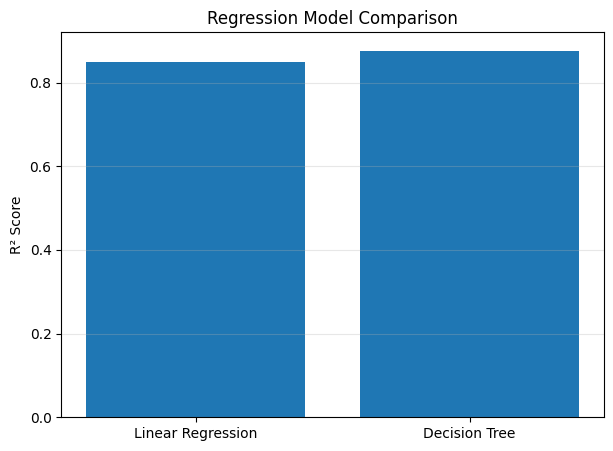

In [37]:
import matplotlib.pyplot as plt

models = ["Linear Regression", "Decision Tree"]
r2_scores = [r2, dt_r2]

plt.figure(figsize=(7, 5))
plt.bar(models, r2_scores)
plt.ylabel("R² Score")
plt.title("Regression Model Comparison")
plt.grid(axis="y", alpha=0.3)
plt.show()

### 📊 7.1 Logistic Regression Performance Metrics

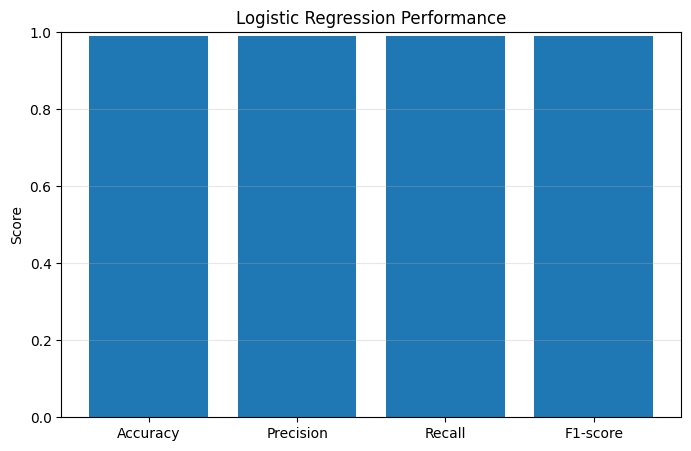

In [38]:
metrics_names = ["Accuracy", "Precision", "Recall", "F1-score"]
metrics_values = [accuracy, precision, recall, f1]

plt.figure(figsize=(8, 5))
plt.bar(metrics_names, metrics_values)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Logistic Regression Performance")
plt.grid(axis="y", alpha=0.3)
plt.show()

## 🔵 8. Student Clustering Using K-Means

In [39]:
from pyspark.ml.clustering import KMeans

print("K-Means imported successfully!")

K-Means imported successfully!


### ⚙️ 8.1 Prepare Clustering Features

In [40]:
cluster_features = [
    "age",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2"
]

cluster_assembler = VectorAssembler(
    inputCols=cluster_features,
    outputCol="cluster_features"
)

cluster_data = cluster_assembler.transform(df)

cluster_data.select(
    "cluster_features"
).show(5, truncate=False)

+----------------------------+
|cluster_features            |
+----------------------------+
|[18.0,2.0,0.0,4.0,0.0,11.0] |
|[17.0,2.0,0.0,2.0,9.0,11.0] |
|[15.0,2.0,0.0,6.0,12.0,13.0]|
|[15.0,3.0,0.0,0.0,14.0,14.0]|
|[16.0,2.0,0.0,0.0,11.0,13.0]|
+----------------------------+
only showing top 5 rows



### 🧠 8.2 Train K-Means Model

In [41]:
kmeans = KMeans(
    featuresCol="cluster_features",
    predictionCol="cluster",
    k=3,
    seed=42
)

kmeans_model = kmeans.fit(cluster_data)

print("K-Means model trained successfully!")

K-Means model trained successfully!


### 📊 8.3 Student Cluster Distribution

In [42]:
cluster_predictions = kmeans_model.transform(cluster_data)
cluster_predictions.groupBy("cluster").count().show()

+-------+-----+
|cluster|count|
+-------+-----+
|      1|  263|
|      2|  278|
|      0|  108|
+-------+-----+



### 🔍 8.4 Cluster Analysis

In [43]:
cluster_predictions.groupBy("cluster").agg(
    {"G1": "avg", "G2": "avg", "studytime": "avg",
     "failures": "avg", "absences": "avg"}
).show()

+-------+------------------+------------------+------------------+------------------+--------------------+
|cluster|           avg(G1)|     avg(absences)|           avg(G2)|    avg(studytime)|       avg(failures)|
+-------+------------------+------------------+------------------+------------------+--------------------+
|      1|13.920152091254753|1.9695817490494296|14.098859315589353| 2.140684410646388|0.015209125475285171|
|      2| 9.492805755395683| 2.064748201438849| 9.643884892086332|1.7949640287769784| 0.34532374100719426|
|      0|10.166666666666666| 11.87962962962963| 10.37037037037037|1.7685185185185186|  0.4074074074074074|
+-------+------------------+------------------+------------------+------------------+--------------------+



### 📈 8.5 Average Grade Across Clusters

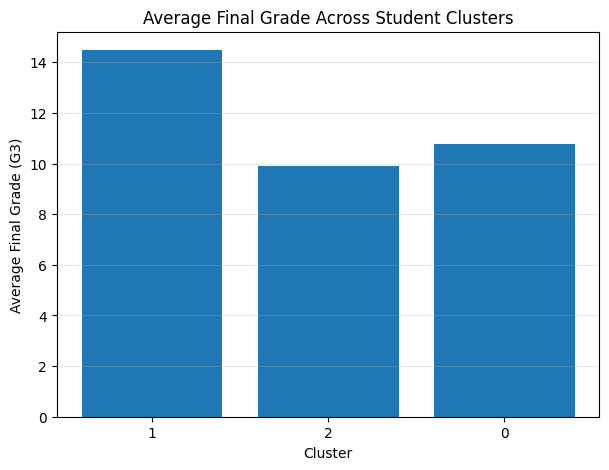

In [44]:
cluster_summary = cluster_predictions.groupBy("cluster").agg(
    {"G3": "avg"}
).toPandas()

plt.figure(figsize=(7, 5))
plt.bar(
    cluster_summary["cluster"].astype(str),
    cluster_summary["avg(G3)"]
)
plt.xlabel("Cluster")
plt.ylabel("Average Final Grade (G3)")
plt.title("Average Final Grade Across Student Clusters")
plt.grid(axis="y", alpha=0.3)
plt.show()

## 🏆 9. Final Regression Results

In [45]:
regression_results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree"],
    "R2 Score": [r2, dt_r2],
    "RMSE": [rmse, dt_rmse],
    "MAE": [mae, dt_mae]
})

print(regression_results.round(4).to_string(index=False))

            Model  R2 Score   RMSE   MAE
Linear Regression    0.8495 1.1764 0.725
    Decision Tree    0.8764 1.0662 0.745


### 🔥 9.1 Final Correlation Heatmap

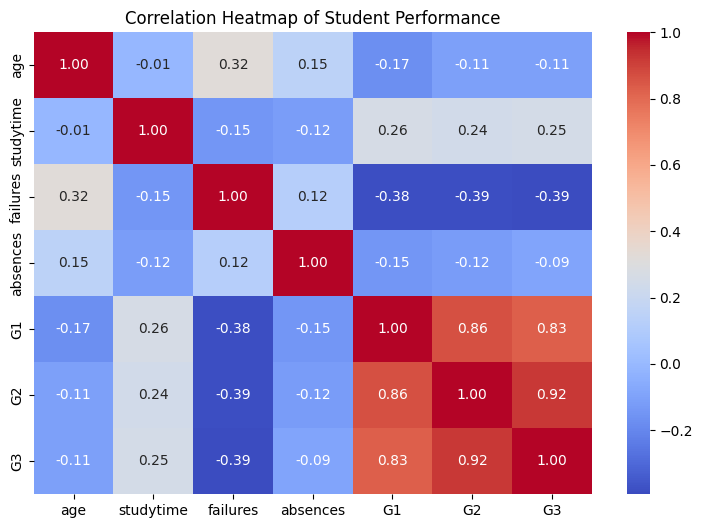

In [46]:
import seaborn as sns
numeric_cols = [
    "age", "studytime", "failures",
    "absences", "G1", "G2", "G3"
]

corr_data = df.select(numeric_cols).toPandas()
corr_matrix = corr_data.corr()

plt.figure(figsize=(9, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap of Student Performance")
plt.show()

### 📋 9.2 Classification Results Summary

In [49]:
import pandas as pd

classification_results = pd.DataFrame({
    "Metric": [
        "Accuracy (%)",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-score"
    ],
    "Score": [
        round(accuracy * 100, 2),
        round(precision, 4),
        round(recall, 4),
        round(f1, 4)
    ]
})

print(classification_results)

               Metric    Score
0        Accuracy (%)  99.0500
1  Weighted Precision   0.9912
2     Weighted Recall   0.9905
3   Weighted F1-score   0.9906


### 💾 9.3 Export Results to CSV

In [50]:
regression_results.to_csv("regression_results.csv", index=False)
classification_results.to_csv("classification_results.csv", index=False)

print("Both result files saved successfully!")

Both result files saved successfully!


### ✅ 9.4 Verify Saved Files

In [51]:
import os
print("Regression CSV exists:",
      os.path.exists("regression_results.csv"))

print("Classification CSV exists:",
      os.path.exists("classification_results.csv"))

Regression CSV exists: True
Classification CSV exists: True


## 🏁 10. Final Results Dashboard

In [52]:
print("REGRESSION RESULTS")
display(regression_results.round(4))

print("CLASSIFICATION RESULTS")
display(classification_results)

REGRESSION RESULTS


,Model,R2 Score,RMSE,MAE
0,Linear Regression,0.8495,1.1764,0.725
1,Decision Tree,0.8764,1.0662,0.745


CLASSIFICATION RESULTS


,Metric,Score
0,Accuracy (%),99.0500
1,Weighted Precision,0.9912
2,Weighted Recall,0.9905
3,Weighted F1-score,0.9906
